# Question 1

For 2025 Myanmar eq (https://earthquake.usgs.gov/earthquakes/eventpage/us7000pn9s/executive) compute the surface wave mag at station MM.KTN (components are accelerometer HNN, HNE, HNZ). \
Remove accelerometer instrum response, integrate data twice to displacement, and bandpass filter each stream btwn 10 & 30 s period. \
Use max displace of 3 streams combined: \
max(sqrt(N^2+E^2+Z^2)) \
useful commands: \
st_rem.remove_response(output="ACC")\
st_rem.integrate()\
st_rem.filter("bandpass",freqmin=1/30,freqmax=1/10)

In [ ]:
#useful commands
#st_rem.remove_response(output="ACC")
#st_rem.integrate()
#st_rem.filter("bandpass",freqmin=1/30,freqmax=1/10)

In [1]:
%pip install obspy -q

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from obspy import read, read_inventory
from obspy.io.xseed import Parser
from obspy.geodetics.base import gps2dist_azimuth, kilometer2degrees
from obspy.geodetics import locations2degrees

In [3]:
client_events = Client("USGS")

events = client_events.get_events(
    starttime=UTCDateTime("2025-03-28"),
    endtime=UTCDateTime("2025-03-29"),
    minmagnitude=7.6,
    maxmagnitude=7.8,
)
print(events.__str__(print_all=True))

1 Event(s) in Catalog:
2025-03-28T06:20:52.715000Z | +22.011,  +95.936 | 7.7  mww | manual


/usr/local/lib/python3.13/dist-packages/obspy/clients/fdsn/client.py:257: ObsPyDeprecationWarning: IRIS is now EarthScope, please consider changing the FDSN client short URL to 'EARTHSCOPE'.
  warnings.warn(msg, ObsPyDeprecationWarning)
/tmp/ipykernel_1632/1252085578.py:9: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client_iris.get_waveforms(


3 Trace(s) in Stream:
MM.KTN..HNE | 2025-03-28T06:20:52.718400Z - 2025-03-28T06:32:38.958400Z | 100.0 Hz, 70625 samples
MM.KTN..HNN | 2025-03-28T06:20:52.718400Z - 2025-03-28T06:32:38.958400Z | 100.0 Hz, 70625 samples
MM.KTN..HNZ | 2025-03-28T06:20:52.718400Z - 2025-03-28T06:32:38.958400Z | 100.0 Hz, 70625 samples


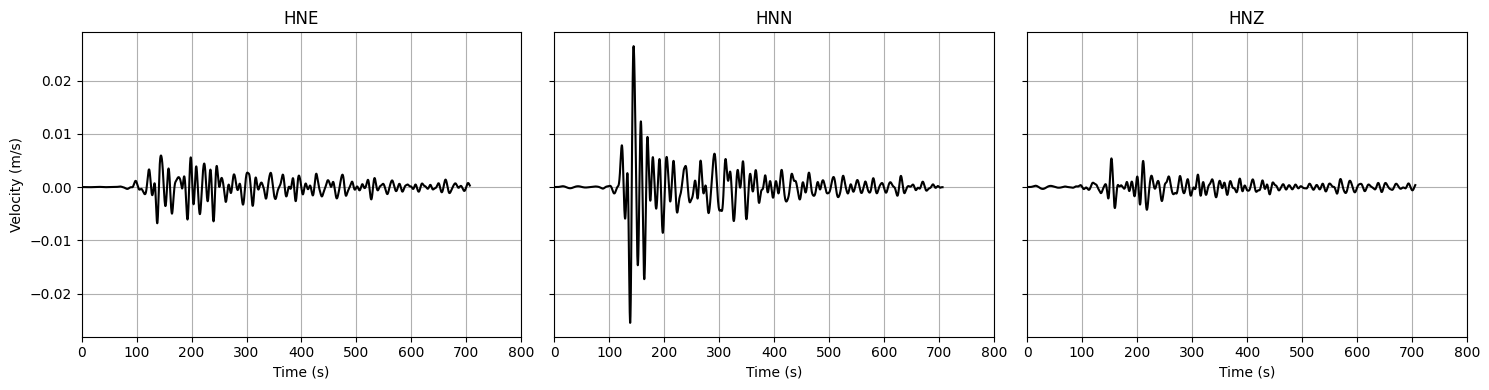

In [16]:
client_iris = Client("IRIS")

event1 = events[0]
origin1 = event1.preferred_origin() or event1.origins[0]
magnitude1 = event1.preferred_magnitude() or event1.magnitudes[0]
t1 = origin1.time

# fetch 3 components of MM.KTN
st = client_iris.get_waveforms(
    network="MM", station="KTN", location="--", channel="HN*",
    starttime=t1, endtime=t1 + 1000,
    attach_response=True
)

st.remove_response(output="ACC") #remove accelerometer response

#integrate twice to convert acceleration to displacement
st.integrate()
st.integrate()

# Bandpass filter each stream between 10 & 30 s period
st.filter("bandpass", freqmin=1/30, freqmax=1/10)

# Display the processed streams
print(st)

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for i, tr in enumerate(st):
    ax[i].plot(tr.times(), tr.data, color="black")
    ax[i].grid(True)
    ax[i].set_xlim(0, 800)
    ax[i].set_title(tr.stats.channel)
    ax[i].set_xlabel("Time (s)")

ax[0].set_ylabel("Velocity (m/s)")
plt.tight_layout()
plt.show()

In [19]:
# Standard formula for surface wave magnitude Ms:
# Ms = log10(A/T) + 1.66 * log10(Delta) + 3.3. eq. 9.71
#A is ground displacement in microns
#T is dominant period of measured waves in seconds (using ~20s as center or max displacement period)
#Delta is distance in degrees (2 <= Delta <= 160)

# align data to have same start
st.interpolate(sampling_rate=st[0].stats.sampling_rate, starttime=max([tr.stats.starttime for tr in st]), endtime=min([tr.stats.endtime for tr in st]))

# Map each trace to its component
E = st.select(channel="HNE")[0]
N = st.select(channel="HNN")[0]
Z = st.select(channel="HNZ")[0]

# Compute sqrt(N^2 + E^2 + Z^2)
combined_displace = np.sqrt(N.data**2 + E.data**2 + Z.data**2)
max_disp = np.max(combined_displace)
print(f"Maximum combined displace amplitude: {max_disp:.6e} meters")

# Compute distance btwn epicenter and KTN to calc surface wave magnitude
# Event coordinates from USGS: +22.011, +95.936
eq_lat = 22.011
eq_lon = 95.936

# KTN: https://ds.iris.edu/mda/MM/KTN/
station_lat = 21.2857
station_lon = 99.589798

dist_deg = locations2degrees(eq_lat, eq_lon, station_lat, station_lon)
dist_km, az, baz = gps2dist_azimuth(eq_lat, eq_lon, station_lat, station_lon)
print(f"Distance btwn station and epicenter: {dist_deg:.3f} degrees ({dist_km/1000:.1f} km)")

#use max displace of three streams combined
A_micrometers = max_disp * 1e6
T_period = 20.0 # see shearer pg 283
ms_mag = np.log10(A_micrometers / T_period) + 1.66 * np.log10(dist_deg) + 3.3
print(f"Computed Surface Wave Magnitude (Ms): {ms_mag:.2f}")


Maximum combined displace amplitude: 2.710913e-02 meters
Distance btwn station and epicenter: 3.473 degrees (386.6 km)
Computed Surface Wave Magnitude (Ms): 7.33
